In [12]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import smarts_cerebellum.globals as gl

lme = pd.read_csv(os.path.join(gl.baseDir, 'lme', 'patients_MNISymC_FaMap_MCP_lme.tsv'), sep = '\t')
lme['Week'] = lme['Week'].astype(int)
lme = lme.sort_values('Week')

obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_MCP_FaMap.tsv'), sep = '\t')
obs = obs[obs.regionname == 'MCP_L']

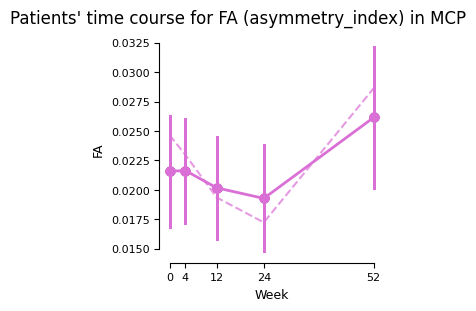

In [13]:
fig, ax = plt.subplots(figsize=(3,3), sharey = True, constrained_layout=True)

lme_ai = lme[(lme.regionname == 'MCP_ai')].sort_values('Week')

obs_ai = obs[obs.regionname == 'MCP_L'].groupby('Week')['asymmetry_index'].mean().reset_index()

ax.errorbar(x = lme_ai['Week'], y = lme_ai['beta'], yerr = lme_ai['se'], fmt = '-o', linewidth = 2, color = 'orchid')
ax.plot(obs_ai['Week'], obs_ai['asymmetry_index'], alpha = .7, linestyle = '--', color = 'orchid')


ax.set_xticks(gl.weeks)
ax.set_ylabel("FA")
ax.set_xlabel("Week")

plt.suptitle(f"Patients' time course for FA (asymmetry_index) in MCP")
sns.despine(trim = True)
plt.show()

<Axes: xlabel='Week', ylabel='mean'>

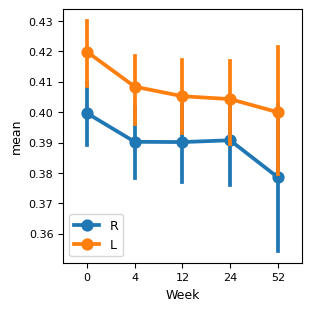

In [14]:
obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_MCP_FaMap.tsv'), sep = '\t')

fig, ax = plt.subplots(figsize=(3,3), sharey = True, constrained_layout=True)
sns.pointplot(x = 'Week', y = 'mean', data = obs[obs.regionname == 'MCP_R'], label = 'R')
sns.pointplot(x = 'Week', y = 'mean', data = obs[obs.regionname == 'MCP_L'], label = 'L')

In [15]:
print(f'---t-test against 0 for asymmetry index of FA in MCP (patients)--- \n')
for week in obs.Week.unique():
    t_val, p_val = stats.ttest_1samp(obs[obs.Week == week]['asymmetry_index'], popmean = 0)
    print(f'Week {week}: t-value = {t_val}, p-value = {p_val} \n')
    

---t-test against 0 for asymmetry index of FA in MCP (patients)--- 

Week 0: t-value = 6.980209114353518, p-value = 3.0122306779635874e-08 

Week 4: t-value = 7.793022778108424, p-value = 6.909079439462168e-10 

Week 12: t-value = 5.542973275466769, p-value = 1.1743281151310071e-06 

Week 24: t-value = 5.134552185788015, p-value = 6.507501047949668e-06 

Week 52: t-value = 5.817197855529206, p-value = 1.3263695329612381e-05 

